# Análisis exploratorio - Airbnb Bogotá

Taller ETL Airbnb de Inteligencia de Negocios. Integrantes: Cristian Andres Agudelo Henao y Jeronimo Patiño Betancur.

En este notebook revisamos cómo vienen los datos de listings, calendar y reviews, qué problemas de calidad tienen
y probamos las transformaciones antes de pasarlas a `src/transformacion.py`. Los datos se leen desde MongoDB con la
clase `Extraccion` del ETL.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from extraccion import Extraccion
from logs import configurar_logs

# La extracción deja su registro en la carpeta logs, igual que el ETL
configurar_logs()
datos = Extraccion().extraer()
listings = datos["listings"]
calendar = datos["calendar"]
reviews = datos["reviews"]

2026-10-11 19:28:56 | INFO | extraccion | Inicio de la extracción


2026-10-11 19:28:56 | INFO | extraccion | Conexión exitosa a MongoDB (mongodb://localhost:27017/), base de datos 'airbnb_bogota'


2026-10-11 19:28:56 | INFO | extraccion | Se leyeron 19187 registros y 90 columnas de 'listings'


2026-10-11 19:29:21 | INFO | extraccion | Se leyeron 7003255 registros y 5 columnas de 'calendar'


2026-10-11 19:29:25 | INFO | extraccion | Se leyeron 527731 registros y 6 columnas de 'reviews'


2026-10-11 19:29:25 | INFO | extraccion | Conexión a MongoDB cerrada


## 2.1 Entendimiento general de los datos

In [2]:
pd.DataFrame({nombre: {"registros": df.shape[0], "columnas": df.shape[1]} for nombre, df in datos.items()}).T

,registros,columnas
listings,19187,90
calendar,7003255,5
reviews,527731,6


### Listings

In [3]:
listings.head(3)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,None,https://a0.muscache.com/pictures/38377482/1df3...,113734,...,4.81,4.93,4.81,112727.0,None,3,3,0,0,0.24
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",None,https://a0.muscache.com/pictures/miso/Hosting-...,321447,...,4.73,4.79,4.70,100613.0,None,24,22,2,0,0.19
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,None,https://a0.muscache.com/pictures/24594394/1ace...,676823,...,4.77,4.91,4.41,NaN,None,1,1,0,0,0.14


In [4]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            19187 non-null  int64  
 1   listing_url                                   19187 non-null  str    
 2   scrape_id                                     19187 non-null  int64  
 3   last_scraped                                  19187 non-null  str    
 4   source                                        19187 non-null  str    
 5   name                                          19187 non-null  str    
 6   description                                   18664 non-null  str    
 7   neighborhood_overview                         0 non-null      object 
 8   picture_url                                   19187 non-null  str    
 9   host_id                                       19187 non-null  int64  
 1

In [5]:
relevantes = ["accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights", "availability_365",
              "number_of_reviews", "review_scores_rating"]
listings[relevantes].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
accommodates,19187.0,3.1,2.1,1.0,2.0,2.0,4.0,16.0
bedrooms,16228.0,1.5,1.6,1.0,1.0,1.0,2.0,50.0
beds,18896.0,1.9,2.1,1.0,1.0,1.0,2.0,50.0
bathrooms,18121.0,1.4,1.4,0.5,1.0,1.0,1.5,50.0
minimum_nights,19183.0,7.0,11.0,1.0,1.0,1.0,3.0,32.0
availability_365,19187.0,306.9,82.1,0.0,269.0,349.0,363.0,365.0
number_of_reviews,19187.0,27.5,74.0,0.0,1.0,8.0,31.0,6162.0
review_scores_rating,14922.0,4.7,0.5,1.0,4.6,4.8,5.0,5.0


- Son 19.187 anuncios con 90 columnas: 22 enteras, 27 decimales, 28 de texto y 13 sin ningún dato. Cada fila es un
  alojamiento con datos del anfitrión, precio, disponibilidad y calificaciones.
- El anuncio típico es para 2 personas (mediana de `accommodates`), con 1 habitación, 1 cama y 1 baño.
- `price` llega como texto (`$284,294.01`), así que hay que pasarlo a número.
- `amenities` es una lista guardada como texto. Es el campo anidado que hay que aplanar.

### Calendar

In [6]:
calendar.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,f,2,1125
1,15410909,2026-06-23,f,2,1125
2,15410909,2026-06-24,f,2,1125
3,15410909,2026-06-25,t,2,1125
4,15410909,2026-06-26,t,2,1125


In [7]:
calendar.info()
print("Fechas:", calendar["date"].min(), "a", calendar["date"].max())
print("Días por anuncio:", calendar.groupby("listing_id").size().unique())
print(calendar["available"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Dtype
---  ------          -----
 0   listing_id      int64
 1   date            str  
 2   available       str  
 3   minimum_nights  int64
 4   maximum_nights  int64
dtypes: int64(3), str(2)
memory usage: 267.2 MB


Fechas: 2026-06-21 a 2027-06-21
Días por anuncio: [365]


available
t    0.841
f    0.159
Name: proportion, dtype: float64


- Son 7.003.255 filas: 365 días para cada uno de los 19.187 anuncios, del 21 de junio de 2026 al 21 de junio de 2027.
  Es un calendario hacia adelante, no un histórico.
- `date` y `available` vienen como texto. `available` es `t` o `f` y el 84 % de las noches aparece disponible.
- Un día no disponible puede ser una reserva o un bloqueo del anfitrión, así que no se puede leer como ocupación.

### Reviews

In [8]:
reviews.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


In [9]:
reviews.info()
print("Fechas:", reviews["date"].min(), "a", reviews["date"].max())
print("Anuncios con al menos una reseña:", reviews["listing_id"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   listing_id     527731 non-null  int64
 1   id             527731 non-null  int64
 2   date           527731 non-null  str  
 3   reviewer_id    527731 non-null  int64
 4   reviewer_name  527731 non-null  str  
 5   comments       527540 non-null  str  
dtypes: int64(3), str(3)
memory usage: 24.2 MB


Fechas: 2010-10-06 a 2026-06-21
Anuncios con al menos una reseña: 14922


- Son 527.731 reseñas entre octubre de 2010 y junio de 2026.
- 14.922 anuncios tienen al menos una reseña. Los demás son anuncios nuevos o sin huéspedes.

### Variables más relevantes

| Variable | Colección | Qué es |
|---|---|---|
| `id` / `listing_id` | listings / calendar, reviews | Identificador del anuncio, une las tres colecciones |
| `host_id` | listings | Identificador del anfitrión |
| `neighbourhood_cleansed` | listings | Localidad de Bogotá |
| `room_type` | listings | Tipo de alojamiento (entero, habitación privada, compartida, hotel) |
| `accommodates`, `bedrooms`, `beds`, `bathrooms` | listings | Capacidad y tamaño del alojamiento |
| `price` | listings | Precio por noche en pesos, como texto |
| `minimum_nights` | listings | Noches mínimas para reservar |
| `availability_365` | listings | Días disponibles en el próximo año |
| `number_of_reviews`, `review_scores_rating` | listings | Cantidad de reseñas y calificación promedio |
| `amenities` | listings | Lista de comodidades del alojamiento |
| `date`, `available` | calendar | Día y si está disponible |
| `date`, `comments` | reviews | Fecha y texto de la reseña |

## 2.2 Calidad de los datos

### Valores nulos

In [10]:
nulos = listings.isna().sum()
nulos = pd.DataFrame({"nulos": nulos, "porcentaje": (nulos / len(listings) * 100).round(1)})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje
neighborhood_overview,19187,100.0
host_since,19187,100.0
host_neighbourhood,19187,100.0
host_thumbnail_url,19187,100.0
host_acceptance_rate,19187,100.0
host_response_rate,19187,100.0
host_response_time,19187,100.0
host_verifications,19187,100.0
host_total_listings_count,19187,100.0
neighbourhood,19187,100.0


In [11]:
print("Nulos en calendar:", calendar.isna().sum().sum())
print("Nulos en reviews:")
print(reviews.isna().sum())

Nulos en calendar: 0
Nulos en reviews:
listing_id         0
id                 0
date               0
reviewer_id        0
reviewer_name      0
comments         191
dtype: int64


- 47 de las 90 columnas de listings tienen nulos y 13 están completamente vacías. Las vacías se descartan.
- Las calificaciones faltan en 4.265 anuncios, que son justo los que no tienen reseñas. No es un error y no
  tiene sentido inventarles una nota, así que se dejan nulas.
- Faltan habitaciones (15,4 %), baños (5,6 %) y camas (1,5 %). Más abajo se revisa cómo completarlos.
- 195 anuncios no tienen precio. Se conservan porque tienen calendario y reseñas.
- Calendar no tiene nulos. En reviews faltan 191 comentarios.

### Registros duplicados

In [12]:
pd.Series({
    "listings (id)": listings.duplicated(subset="id").sum(),
    "calendar (anuncio y fecha)": calendar.duplicated(subset=["listing_id", "date"]).sum(),
    "reviews (id)": reviews.duplicated(subset="id").sum(),
})

listings (id)                 0
calendar (anuncio y fecha)    0
reviews (id)                  0
dtype: int64

No hay duplicados en ninguna colección, así que hoy no hace falta eliminar nada. Igual dejamos el control en el ETL
por si se carga una versión nueva de los datos.

### Valores atípicos

Usamos el rango intercuartílico: un valor es atípico si está por debajo de Q1 - 1,5 IQR o por encima de Q3 + 1,5 IQR.

count        18992.0
mean        446027.0
std        8829057.0
min          19181.0
25%         110000.0
50%         161460.0
75%         230346.0
max      448176567.0
Name: price, dtype: float64
Límite superior IQR: 410866
Por encima del límite: 1410
Mayores a 5 millones por noche: 38


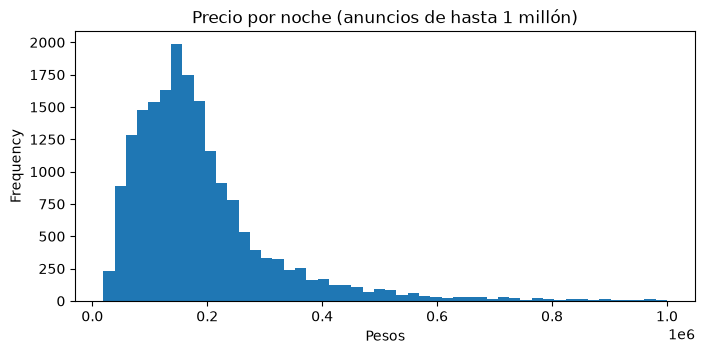

In [13]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


precio = pd.to_numeric(listings["price"].str.replace(r"[$,]", "", regex=True))
print(precio.describe().round(0))
print("Límite superior IQR:", round(limites_iqr(precio.dropna())[1]))
print("Por encima del límite:", (precio > limites_iqr(precio.dropna())[1]).sum())
print("Mayores a 5 millones por noche:", (precio > 5_000_000).sum())

ax = precio[precio <= 1_000_000].plot.hist(bins=50, figsize=(8, 3.5))
ax.set_title("Precio por noche (anuncios de hasta 1 millón)")
ax.set_xlabel("Pesos")
plt.show()

**price**
- La mediana es 161.460 pesos por noche y la mitad de los anuncios está entre 110.000 y 230.000.
- 1.410 anuncios pasan el límite del IQR (411 mil). La mayoría son alojamientos grandes o de lujo, son reales y se
  dejan.
- Lo que no es real son los 38 anuncios de más de 5 millones por noche, con un máximo de 448 millones. Los tomamos
  como errores de captura y quedan nulos.
- Con esta distribución definimos los rangos de precio: Económico (menos de 100 mil), Medio (100 a 250 mil),
  Alto (250 a 500 mil) y Lujo (500 mil o más).

count    19183.0
mean         7.0
std         11.0
min          1.0
25%          1.0
50%          1.0
75%          3.0
max         32.0
Name: minimum_nights, dtype: float64
Límite superior IQR: 6.0
Anuncios con 28 noches o más: 3414


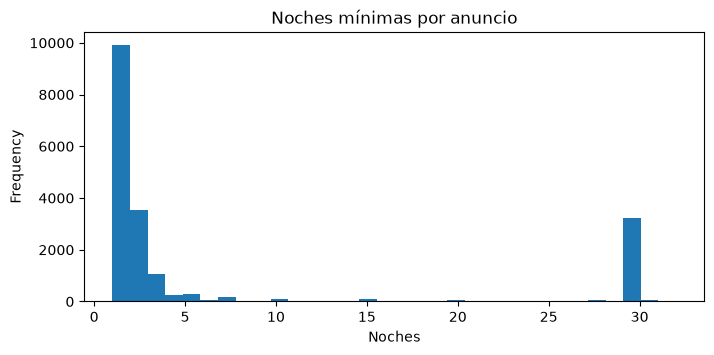

In [14]:
noches = listings["minimum_nights"]
print(noches.describe().round(1))
print("Límite superior IQR:", limites_iqr(noches.dropna())[1])
print("Anuncios con 28 noches o más:", (noches >= 28).sum())

ax = noches.plot.hist(bins=32, figsize=(8, 3.5))
ax.set_title("Noches mínimas por anuncio")
ax.set_xlabel("Noches")
plt.show()

**minimum_nights**
- La mediana es 1 noche y el 75 % pide 3 o menos. El máximo es 32, así que no hay valores imposibles.
- El IQR marca como atípicos a 4.053 anuncios, pero no son errores: hay dos grupos, estadías cortas (1 a 3 noches) y
  3.414 anuncios que piden 28 noches o más, que son alquileres por mes. Por eso no se elimina ninguno.

count    19187.0
mean       306.9
std         82.1
min          0.0
25%        269.0
50%        349.0
75%        363.0
max        365.0
Name: availability_365, dtype: float64
Límite inferior IQR: 128.0
Anuncios con 365 días disponibles: 3508
De esos, sin reseñas en el último año: 2158


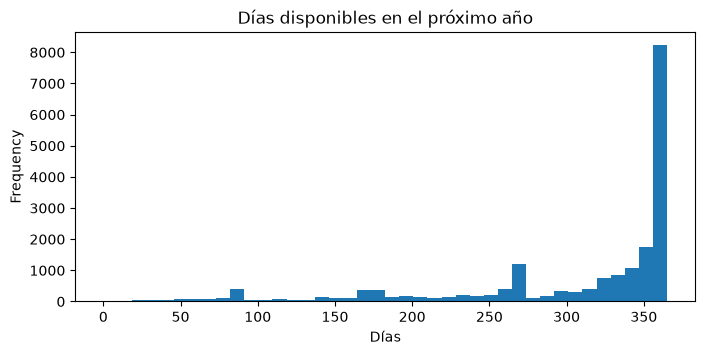

In [15]:
disponibilidad = listings["availability_365"]
print(disponibilidad.describe().round(1))
print("Límite inferior IQR:", limites_iqr(disponibilidad)[0])
print("Anuncios con 365 días disponibles:", (disponibilidad == 365).sum())
print("De esos, sin reseñas en el último año:",
      ((disponibilidad == 365) & (listings["number_of_reviews_ltm"] == 0)).sum())

ax = disponibilidad.plot.hist(bins=40, figsize=(8, 3.5))
ax.set_title("Días disponibles en el próximo año")
ax.set_xlabel("Días")
plt.show()

**availability_365**
- Todos los valores están entre 0 y 365, no hay errores. La mediana es 349 días: casi todo está disponible.
- Los atípicos por IQR son los 1.129 anuncios con menos de 128 días disponibles, que son los más reservados o bloqueados.
- 3.508 anuncios tienen los 365 días libres y 2.158 de ellos no tuvieron reseñas en el último año. Parecen anuncios
  inactivos, pero no hay forma de confirmarlo, así que se dejan.

## 2.3 Posibles transformaciones

### Desanidar amenities

In [16]:
print(listings["amenities"].iloc[0][:150], "...")

comodidades = listings["amenities"].map(json.loads).explode().dropna().reset_index(drop=True)
print("Filas al aplanar:", len(comodidades))
print("Comodidades distintas:", comodidades.nunique())

["Blender", "Luggage dropoff allowed", "Long term stays allowed", "Children\u2019s dinnerware", "Drying rack for clothing", "Free parking on premises" ...


Filas al aplanar:

 505595
Comodidades distintas: 3690


In [17]:
# Prueba de normalización: minúsculas, sin tildes ni caracteres especiales y sin la velocidad del internet
normalizada = (
    comodidades.astype(str).str.lower().str.normalize("NFKD")
    .str.encode("ascii", errors="ignore").str.decode("ascii")
    .str.replace(r"\s+", " ", regex=True).str.strip()
    .str.replace(r"\s*\d+ mbps$", "", regex=True)
)
print("Comodidades distintas después de normalizar:", normalizada.nunique())

ejemplos = pd.DataFrame({"antes": comodidades, "despues": normalizada})
ejemplos[comodidades.str.contains("Mbps|’")].drop_duplicates().head(6)

Comodidades distintas después de normalizar: 3069


,antes,despues
3,Children’s dinnerware,childrens dinnerware
43,Children’s books and toys,childrens books and toys
135,Fast wifi – 143 Mbps,fast wifi
414,Fast wifi – 113 Mbps,fast wifi
641,Fast wifi – 234 Mbps,fast wifi
713,Pack ’n play/Travel crib,pack n play/travel crib


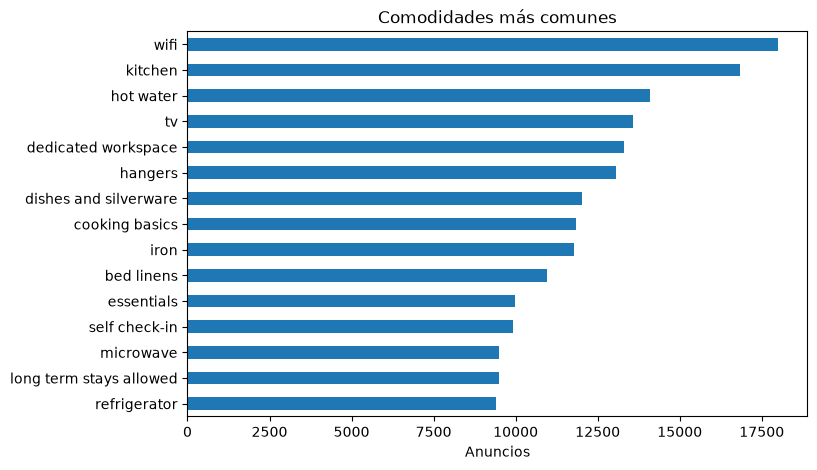

In [18]:
ax = normalizada.value_counts().head(15).sort_values().plot.barh(figsize=(8, 5))
ax.set_title("Comodidades más comunes")
ax.set_xlabel("Anuncios")
ax.set_ylabel("")
plt.show()

- Cada anuncio guarda sus comodidades en una lista dentro de un texto. Así no se puede contar, por ejemplo, cuántos
  anuncios tienen parqueadero.
- **Sí hay que desanidar.** Al aplanar queda una fila por anuncio y comodidad (505.595 filas), que será la tabla
  `anuncio_comodidades`.
- Al normalizar el texto pasamos de 3.690 a 3.069 comodidades distintas.
- Wifi y cocina están en casi todos los anuncios, así que no diferencian mucho. Parqueadero, lavadora y espacio de
  trabajo sí separan unos anuncios de otros. Esas cinco se agregan como columnas de sí o no en anuncios.

### Información del host

In [19]:
columnas_host = [c for c in listings.columns if c.startswith("host_")]
print(len(columnas_host), "columnas del anfitrión:", columnas_host)

anuncios_por_host = listings.groupby("host_id").size()
print("Anfitriones distintos:", len(anuncios_por_host))
print("Con un solo anuncio:", round((anuncios_por_host == 1).mean() * 100, 1), "%")
print("Con 10 o más anuncios:", (anuncios_por_host >= 10).sum())
print("Columnas del host completamente vacías:", listings[columnas_host].isna().all().sum())

20 columnas del anfitrión: ['host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified']
Anfitriones distintos: 8335
Con un solo anuncio: 71.5 %
Con 10 o más anuncios: 295
Columnas del host completamente vacías: 8


- Hay 20 columnas del anfitrión que se repiten en cada uno de sus anuncios: 8.335 anfitriones para 19.187 anuncios.
- 8 de esas columnas vienen vacías y otras son enlaces y fotos del perfil.
- **Decisión:** no armamos una tabla aparte de anfitriones porque ninguna de nuestras preguntas la usa. En anuncios
  solo dejamos `id_anfitrion`, que basta para contar anuncios por anfitrión si se necesita.

### Agrupar el calendario por mes

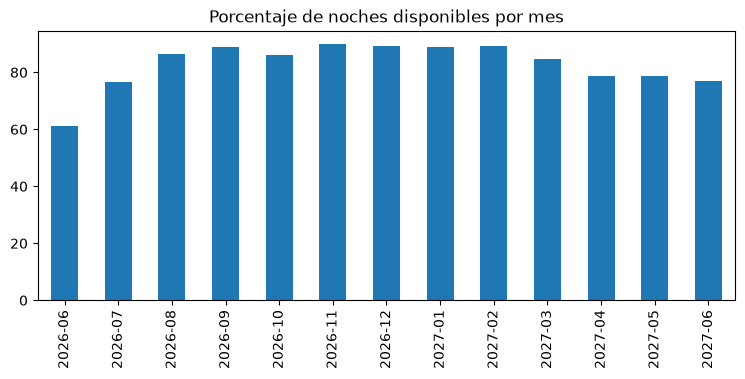

In [20]:
mes = calendar["date"].str[:7]
ax = (calendar["available"].eq("t").groupby(mes).mean() * 100).plot.bar(figsize=(9, 3.5))
ax.set_title("Porcentaje de noches disponibles por mes")
ax.set_xlabel("")
plt.show()

- Los meses cercanos a la fecha de captura tienen menos noches disponibles (61 % en junio de 2026 y 77 % en julio)
  porque las reservas se hacen con poca anticipación. De agosto a febrero sube a casi 90 %.
- **Sí conviene resumir.** El calendario diario tiene 7 millones de filas y no cabe en Excel (máximo 1.048.576). Se
  deja completo en SQLite y además se crea `calendario_mensual`, con los días disponibles por anuncio y mes.

### Estandarizar formatos de fecha, moneda y texto

In [21]:
print("Precio:", listings["price"].dropna().head(3).tolist())
print("Fechas:", reviews["date"].head(3).tolist())
print("Disponible:", calendar["available"].unique().tolist())
print("Máximo de noches en calendar:", calendar["maximum_nights"].max())
print("Comentarios con etiquetas HTML:", reviews["comments"].str.contains("<br", na=False).sum())
print("Localidades:", sorted(listings["neighbourhood_cleansed"].unique()))

Precio: ['$284,294.01', '$215,000.00', '$99,196.10']
Fechas: ['2010-10-06', '2010-11-22', '2011-01-19']
Disponible: ['f', 't']
Máximo de noches en calendar: 2147483647


Comentarios con etiquetas HTML: 69375
Localidades: ['Antonio Nariño', 'Barrios Unidos', 'Bosa', 'Candelaria', 'Chapinero', 'Ciudad Bolivar', 'Engativa', 'Fontibon', 'Kennedy', 'Los Martires', 'Puente Aranda', 'Rafael Uribe Uribe', 'San Cristobal', 'Santa Fe', 'Suba', 'Sumapaz', 'Teusaquillo', 'Tunjuelito', 'Usaquen', 'Usme']


- **Fecha:** ya viene como `AAAA-MM-DD`, pero como texto. Se convierte y de ahí se sacan año, mes, día y trimestre.
- **Moneda:** el precio está en pesos con signo y comas. Se quitan y se pasa a número.
- **Texto:** 69.375 comentarios tienen etiquetas HTML como `<br/>`. Las localidades vienen sin tilde (Usaquen,
  Engativa, Fontibon...) menos Antonio Nariño; se corrigen al nombre oficial.
- `maximum_nights` tiene el valor 2.147.483.647, que es un relleno del sistema y no un dato real. No la necesitamos,
  así que se descarta.

In [22]:
print("Tipo de alojamiento de los anuncios sin habitaciones:")
print(listings.loc[listings["bedrooms"].isna(), "room_type"].value_counts())

texto = listings["bathrooms_text"].str.lower().str.replace("half-bath", "0.5")
banos_texto = pd.to_numeric(texto.str.extract(r"([\d.]+)")[0])
print("Baños nulos que se recuperan desde el texto:", (listings["bathrooms"].isna() & banos_texto.notna()).sum())
listings.loc[listings["bathrooms"].isna(), ["bathrooms_text"]].assign(banos=banos_texto).head()

Tipo de alojamiento de los anuncios sin habitaciones:
room_type
Private room       2560
Entire home/apt     347
Shared room          52
Name: count, dtype: int64
Baños nulos que se recuperan desde el texto: 1044


,bathrooms_text,banos
0,2.5 baths,2.5
7,NaN,NaN
15,1 bath,1.0
34,1 bath,1.0
36,1 bath,1.0


- De los 2.959 anuncios sin habitaciones, 2.612 son habitaciones privadas o compartidas. En esos casos tiene sentido
  poner 1. Para los demás usamos la mediana de los anuncios con la misma capacidad.
- 1.044 de los 1.066 baños nulos se recuperan del texto `bathrooms_text` ("1 private bath", "Half-bath"). Los 22
  restantes se completan con la mediana.

## Correlaciones

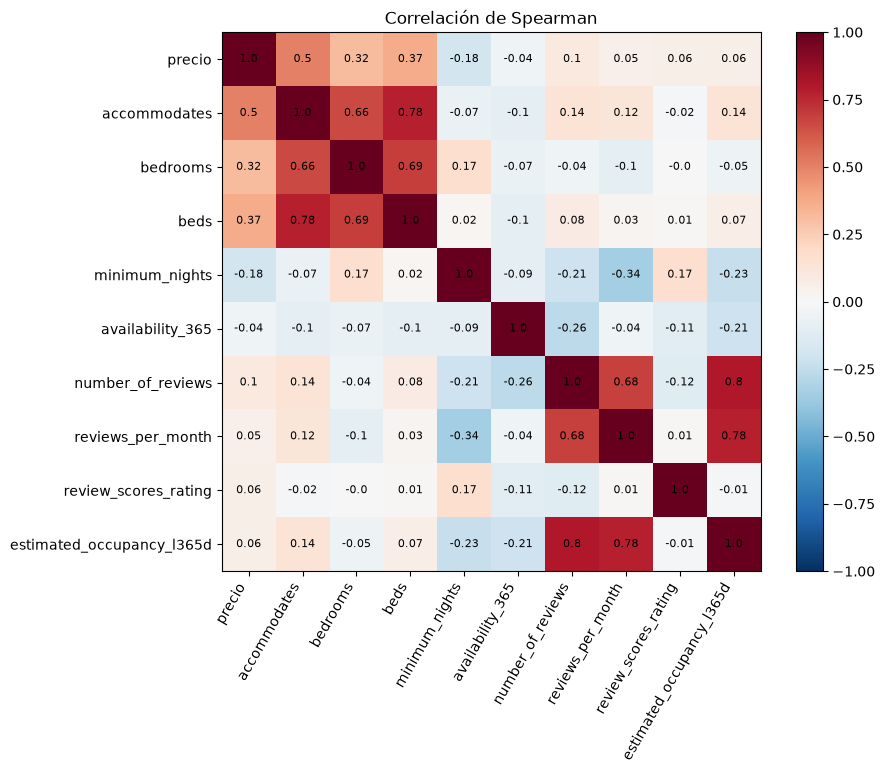

In [23]:
numericas = listings.assign(precio=precio.where(precio <= 5_000_000))[[
    "precio", "accommodates", "bedrooms", "beds", "minimum_nights", "availability_365",
    "number_of_reviews", "reviews_per_month", "review_scores_rating", "estimated_occupancy_l365d",
]]
# Spearman porque hay muchos atípicos y relaciones que no son lineales
correlacion = numericas.corr(method="spearman").round(2)

fig, ax = plt.subplots(figsize=(9, 7))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacion)), correlacion.columns, rotation=60, ha="right")
ax.set_yticks(range(len(correlacion)), correlacion.columns)
for i in range(len(correlacion)):
    for j in range(len(correlacion)):
        ax.text(j, i, correlacion.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(imagen)
ax.set_title("Correlación de Spearman")
plt.show()

- El precio se relaciona sobre todo con la capacidad (0,50), las camas (0,37) y las habitaciones (0,32): más grande,
  más caro.
- La calificación y la cantidad de reseñas casi no tienen que ver con el precio.
- `number_of_reviews` y `reviews_per_month` se relacionan fuerte con `estimated_occupancy_l365d` (0,80 y 0,78).
  Inside Airbnb calcula la ocupación a partir de las reseñas, así que son prácticamente la misma información.

## Primera mirada a las preguntas de negocio

room_type
Entire home/apt    182589.0
Hotel room         193048.0
Private room        91295.0
Shared room         41453.0
Name: precio, dtype: float64


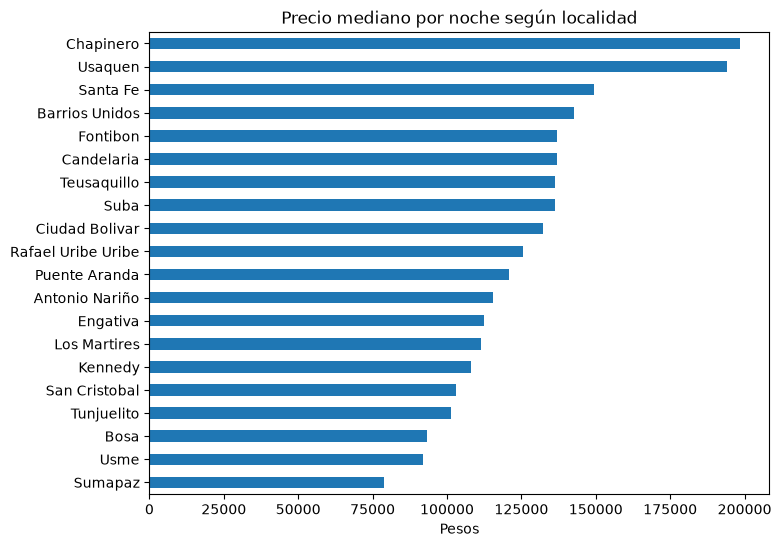

In [24]:
base = listings.assign(precio=precio.where(precio <= 5_000_000))
print(base.groupby("room_type")["precio"].median().round(0))

ax = base.groupby("neighbourhood_cleansed")["precio"].median().sort_values().plot.barh(figsize=(8, 6))
ax.set_title("Precio mediano por noche según localidad")
ax.set_xlabel("Pesos")
ax.set_ylabel("")
plt.show()

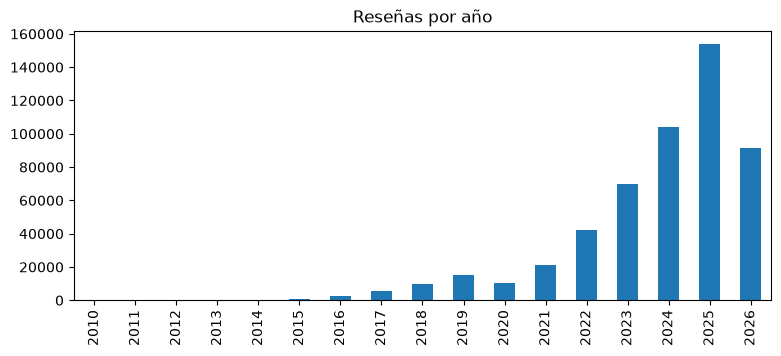

In [25]:
ax = reviews["date"].str[:4].value_counts().sort_index().plot.bar(figsize=(9, 3.5))
ax.set_title("Reseñas por año")
ax.set_xlabel("")
plt.show()

- Un alojamiento entero cuesta el doble que una habitación privada (182 mil contra 91 mil de mediana).
- Chapinero y Usaquén son las localidades más caras, cerca de 200 mil por noche, y también las que tienen más
  anuncios. Las del sur quedan alrededor de 100 mil.
- Las reseñas crecen cada año, con una caída en 2020 por la pandemia, y llegan a 154.156 en 2025. 2026 está incompleto.

## 2.4 Hallazgos

**Inconsistencias detectadas**
- Precios imposibles: 38 anuncios cobran más de 5 millones por noche, uno de ellos 448 millones.
- `maximum_nights` tiene un valor de relleno (2.147.483.647) en listings y calendar.
- Las localidades están escritas sin tilde, menos Antonio Nariño.
- 69.375 comentarios traen etiquetas HTML.

**Variables problemáticas**
- `price`: texto con signo, comas y extremos.
- `amenities`: lista anidada con 3.690 variantes de texto.
- `bathrooms`: el dato faltante sí está, pero escrito en `bathrooms_text`.
- `review_scores_rating`: 22 % de nulos que se explican porque esos anuncios no tienen reseñas.

**Correlaciones**
- La capacidad es lo que más se relaciona con el precio.
- Reseñas y ocupación estimada son la misma señal.

**Outliers**
- En `price` se dejan los anuncios caros reales y se anulan solo los de más de 5 millones.
- En `minimum_nights` y `availability_365` los atípicos son comportamientos reales (estadías por mes, anuncios muy
  reservados), así que no se eliminan.

**Decisiones para la transformación**
- Pasar el precio a número, anular los mayores a 5 millones y crear rangos de precio.
- Completar habitaciones, camas, baños y noches mínimas; dejar nula la calificación.
- Aplanar `amenities` en una tabla aparte y agregar cinco comodidades como columnas de sí o no.
- No separar la información del host.
- Convertir las fechas y sacar año, mes, día y trimestre; resumir el calendario por mes.
- Limpiar el HTML de los textos, corregir las localidades y traducir el tipo de alojamiento.
- Dejar el control de duplicados aunque hoy no haya.

El detalle de cada transformación y su justificación está en el informe (`doc/informe_etl_airbnb.pdf`).